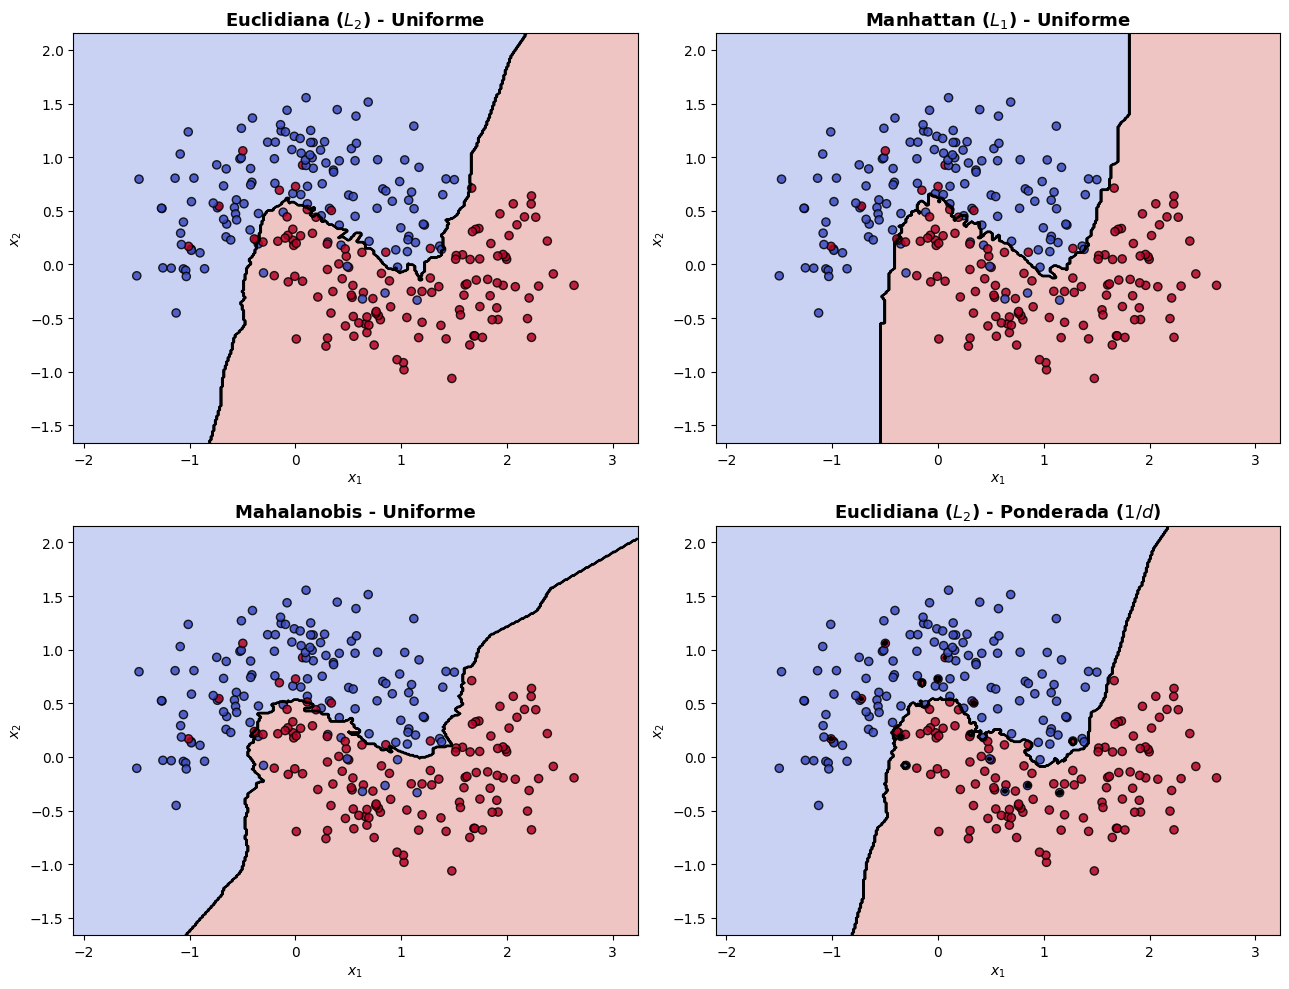

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# gerar dados sintéticos não-lineares (duas luas com ruído)
X, y = make_moons(n_samples=250, noise=0.30, random_state=42)

# covariância empírica para a distância de Mahalanobis
cov_matrix = np.cov(X, rowvar=False)

# configurar os 4 cenários comparativos (fixando K=15 para visualizar a forma da fronteira) <- ALTERE OS VALORES DE K PARA VER COMO A SUPERFICIE SE COMPORTA
configs = [
    {
        'title': 'Euclidiana ($L_2$) - Uniforme',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'euclidean'}
    },
    {
        'title': 'Manhattan ($L_1$) - Uniforme',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'manhattan'}
    },
    {
        'title': 'Mahalanobis - Uniforme',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'mahalanobis',
                   'metric_params': {'VI': np.linalg.pinv(cov_matrix)}}
    },
    {
        'title': 'Euclidiana ($L_2$) - Ponderada ($1/d$)',
        'params': {'n_neighbors': 15, 'weights': 'distance', 'metric': 'euclidean'}
    }
]

# grid para desenhar as superfícies de decisão
x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Plotagem
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for i, cfg in enumerate(configs):
    clf = KNeighborsClassifier(**cfg['params'])
    clf.fit(X, y)

    # ppredição contínua ou discreta no grid
    Z = clf.predict(grid_points).reshape(xx.shape)

    ax = axes[i]
    # fronteira de decisão e regiões
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.contour(xx, yy, Z, colors='k', linewidths=1.2)

    # Amostras de treino
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm,
                         edgecolors='k', s=35, alpha=0.85)

    ax.set_title(cfg['title'], fontsize=13, fontweight='bold')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

plt.tight_layout()
plt.show()

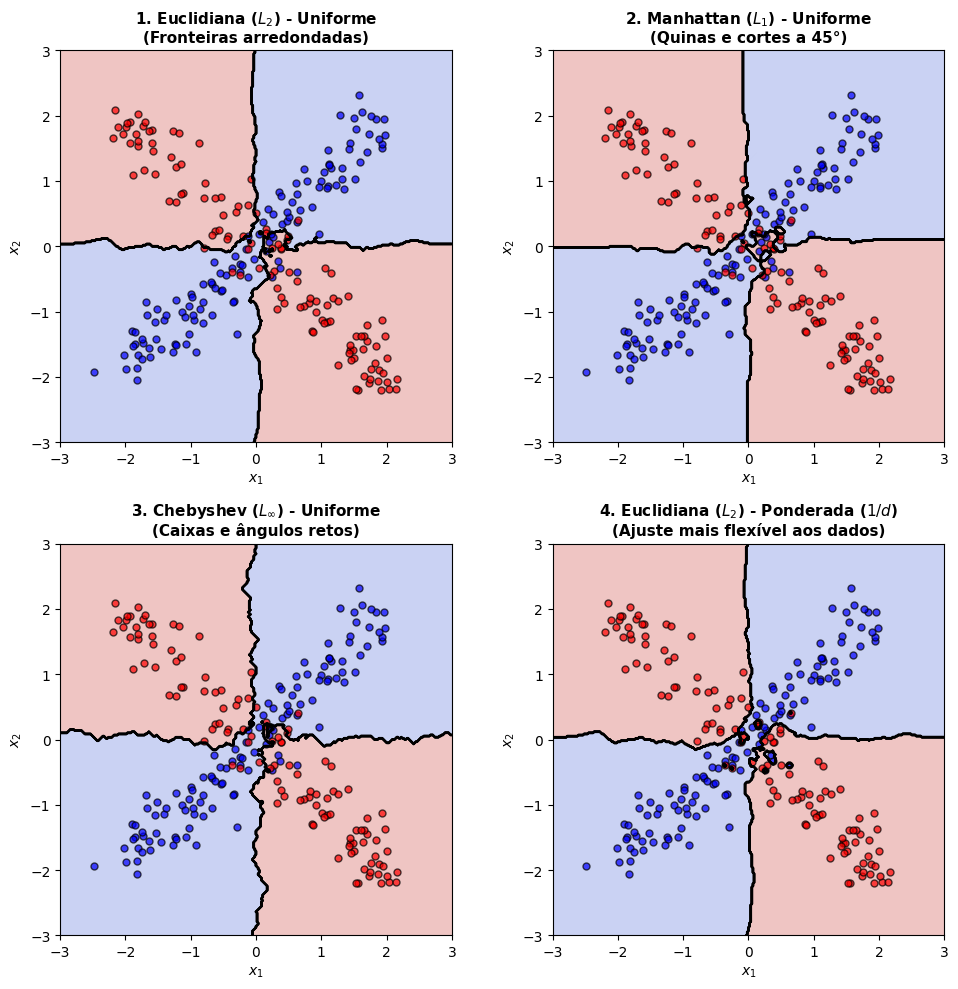

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(42)

# dados limpos em formato de cruz/diagonal
n = 120
# Classe 0: diagonal principal
s0 = np.random.uniform(-2, 2, n)
X0 = np.column_stack([s0, s0]) + np.random.normal(0, 0.25, size=(n, 2))

# Classe 1: diagonal secundária
s1 = np.random.uniform(-2, 2, n)
X1 = np.column_stack([s1, -s1]) + np.random.normal(0, 0.25, size=(n, 2))

X = np.vstack([X0, X1])
y = np.array([0] * n + [1] * n)

# configuração dos 4 cenários (K=15 fixo para todos) <- ALTERE OS VALORES DE K PARA VER O COMPORTAMENTO
configs = [
    {
        'title': '1. Euclidiana ($L_2$) - Uniforme\n(Fronteiras arredondadas)',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'euclidean'}
    },
    {
        'title': '2. Manhattan ($L_1$) - Uniforme\n(Quinas e cortes a 45°)',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'manhattan'}
    },
    {
        'title': '3. Chebyshev ($L_\\infty$) - Uniforme\n(Caixas e ângulos retos)',
        'params': {'n_neighbors': 15, 'weights': 'uniform', 'metric': 'chebyshev'}
    },
    {
        'title': '4. Euclidiana ($L_2$) - Ponderada ($1/d$)\n(Ajuste mais flexível aos dados)',
        'params': {'n_neighbors': 15, 'weights': 'distance', 'metric': 'euclidean'}
    }
]

#  Grid
grid_range = np.linspace(-3, 3, 350)
xx, yy = np.meshgrid(grid_range, grid_range)
grid = np.c_[xx.ravel(), yy.ravel()]

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.ravel()

for i, cfg in enumerate(configs):
    clf = KNeighborsClassifier(**cfg['params'])
    clf.fit(X, y)

    Z = clf.predict(grid).reshape(xx.shape)

    ax = axes[i]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.contour(xx, yy, Z, colors='black', linewidths=1.3)

    ax.scatter(X0[:, 0], X0[:, 1], c='blue', edgecolors='k', s=25, alpha=0.7, label='Classe 0')
    ax.scatter(X1[:, 0], X1[:, 1], c='red', edgecolors='k', s=25, alpha=0.7, label='Classe 1')

    ax.set_title(cfg['title'], fontsize=11, fontweight='bold')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

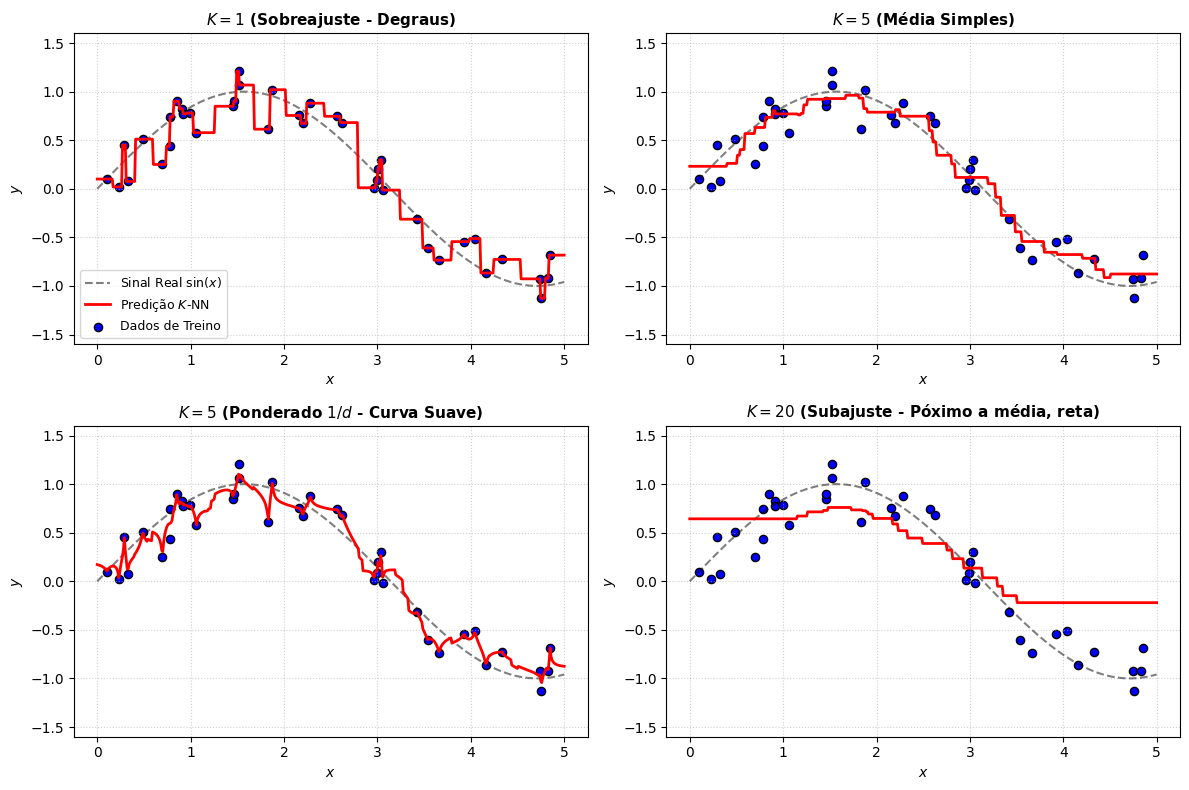

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

np.random.seed(42)

# gera dados sintéticos unidimensionais - função seno
X_train = np.sort(np.random.uniform(0, 5, 40))[:, np.newaxis]
y_train = np.sin(X_train).ravel() + np.random.normal(0, 0.2, X_train.shape[0])

# Grid para traçar as curvas de predição
X_test = np.linspace(0, 5, 500)[:, np.newaxis]
y_true = np.sin(X_test).ravel()

# configurações para comparação
models = [
    {'title': r'$K=1$ (Sobreajuste - Degraus)', 'k': 1, 'weights': 'uniform'},
    {'title': r'$K=5$ (Média Simples)', 'k': 5, 'weights': 'uniform'},
    {'title': r'$K=5$ (Ponderado $1/d$ - Curva Suave)', 'k': 5, 'weights': 'distance'},
    {'title': r'$K=20$ (Subajuste - Póximo a média, reta)', 'k': 20, 'weights': 'uniform'}
]

# 3. Plotagem
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, cfg in enumerate(models):
    knn = KNeighborsRegressor(n_neighbors=cfg['k'], weights=cfg['weights'])
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    ax = axes[i]
    ax.plot(X_test, y_true, 'k--', alpha=0.5, label=r'Sinal Real $\sin(x)$')
    ax.plot(X_test, y_pred, 'r-', linewidth=2, label=r'Predição $K$-NN')
    ax.scatter(X_train, y_train, c='blue', edgecolors='k', s=35, label='Dados de Treino')

    ax.set_title(cfg['title'], fontsize=11, fontweight='bold')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_ylim(-1.6, 1.6)
    ax.grid(True, linestyle=':', alpha=0.6)
    if i == 0:
        ax.legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()

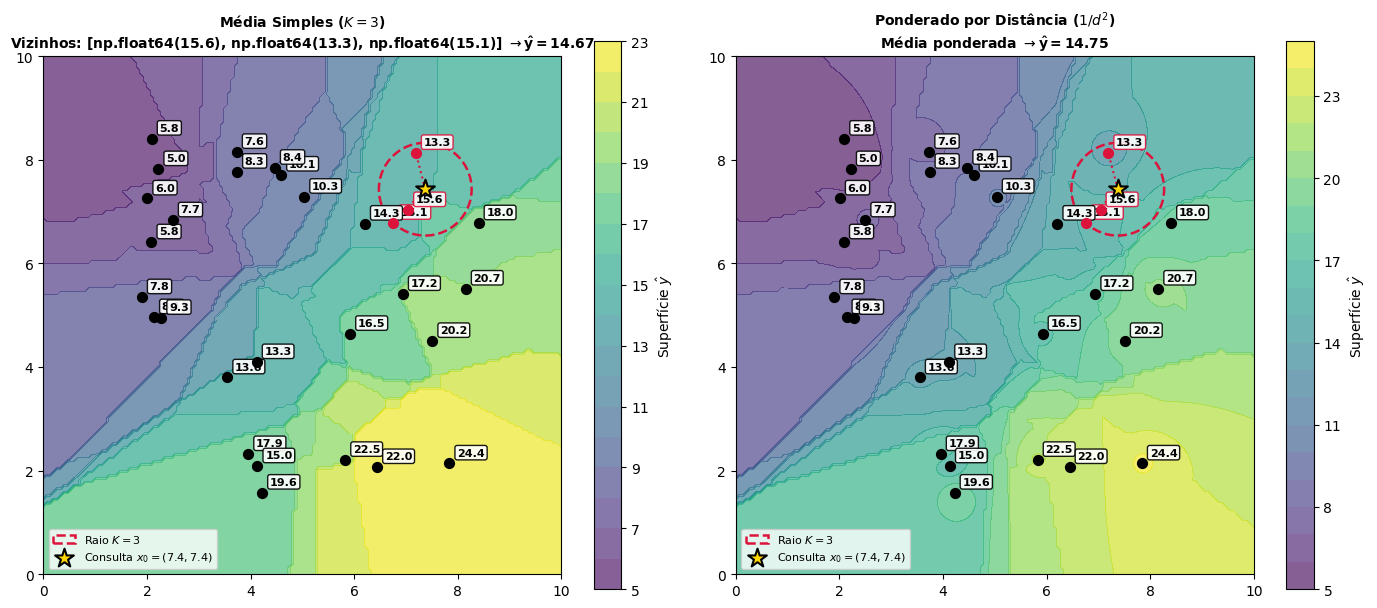

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

# 1. Base fixa de treino)
# np.random.seed(42)

N_TRAIN = 30 #altere aqui a quantidade de dados de treino
X_train = np.random.uniform(1.5, 8.5, size=(N_TRAIN, 2))
y_train = np.round(2.0 * X_train[:, 0] - 1.5 * X_train[:, 1] + 12 + np.random.normal(0, 1.0, N_TRAIN), 1)

# grid fixo para as superfícies de decisão
x_grid = np.linspace(0, 10, 150)
xx, yy = np.meshgrid(x_grid, x_grid)
X_grid = np.c_[xx.ravel(), yy.ravel()]

# modelos treinados
K = 3
knn_unif = KNeighborsRegressor(n_neighbors=K, weights='uniform').fit(X_train, y_train)
knn_dist = KNeighborsRegressor(n_neighbors=K, weights='distance').fit(X_train, y_train)

Z_unif = knn_unif.predict(X_grid).reshape(xx.shape)
Z_dist = knn_dist.predict(X_grid).reshape(xx.shape)


def demonstrar_knn_2d(x0_custom=None):
    """
    Sorteia um novo ponto x0 (ou usa x0_custom) e plota a regressão.
    """
    if x0_custom is None:
        x0 = np.random.uniform(2.5, 7.5, size=(1, 2))
    else:
        x0 = np.array(x0_custom).reshape(1, 2)

    # identificar os K vizinhos de x0
    dists, indices = knn_unif.kneighbors(x0)
    k_idx = indices[0]
    k_dists = dists[0]
    radius = k_dists[-1]

    # cálculos analíticos para mostrar no título
    y_vizinhos = y_train[k_idx]
    pred_unif = knn_unif.predict(x0)[0]

    pesos = 1.0 / (k_dists**2 + 1e-5)
    pred_dist = knn_dist.predict(x0)[0]

    # plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    cenarios = [
        {
            'ax': axes[0],
            'Z': Z_unif,
            'title': f'Média Simples ($K={K}$)\n' +
                     f'Vizinhos: {list(y_vizinhos)} $\\to \\mathbf{{\\hat{{y}} = {pred_unif:.2f}}}$'
        },
        {
            'ax': axes[1],
            'Z': Z_dist,
            'title': f'Ponderado por Distância ($1/d^2$)\n' +
                     f'Média ponderada $\\to \\mathbf{{\\hat{{y}} = {pred_dist:.2f}}}$'
        }
    ]

    for c in cenarios:
        ax = c['ax']
        im = ax.contourf(xx, yy, c['Z'], levels=20, cmap='viridis', alpha=0.65)
        plt.colorbar(im, ax=ax, label=r'Superfície $\hat{y}$')

        # círculo da vizinhança - o modelo não gera isso, isso é feito só para fins didáticos / visualização
        circulo = plt.Circle((x0[0, 0], x0[0, 1]), radius, color='crimson', fill=False,
                             linestyle='--', linewidth=1.8, label=f'Raio $K={K}$')
        ax.add_patch(circulo)

        # linhas de conexão
        for idx in k_idx:
            ax.plot([x0[0, 0], X_train[idx, 0]], [x0[0, 1], X_train[idx, 1]],
                    color='crimson', linestyle=':', linewidth=1.5)

        # pontos de treino com valores de y
        for i in range(N_TRAIN):
            is_k = i in k_idx
            cor = 'crimson' if is_k else 'black'
            ax.scatter(X_train[i, 0], X_train[i, 1], c=cor, s=50, zorder=4)
            ax.annotate(f"{y_train[i]}", (X_train[i, 0]+0.15, X_train[i, 1]+0.15),
                        fontsize=8, fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor=cor))

        # ponto sorteado de teste
        ax.scatter(x0[0, 0], x0[0, 1], c='gold', s=200, marker='*',
                   edgecolors='black', linewidth=1.5, zorder=5,
                   label=f'Consulta $x_0=({x0[0,0]:.1f}, {x0[0,1]:.1f})$')

        ax.set_title(c['title'], fontsize=10, fontweight='bold')
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 10)
        ax.set_aspect('equal')
        ax.legend(loc='lower left', fontsize=8)

    plt.tight_layout()
    plt.show()

# Para testar: rode várias vezes para ver x0 mudar a cada execução
demonstrar_knn_2d()

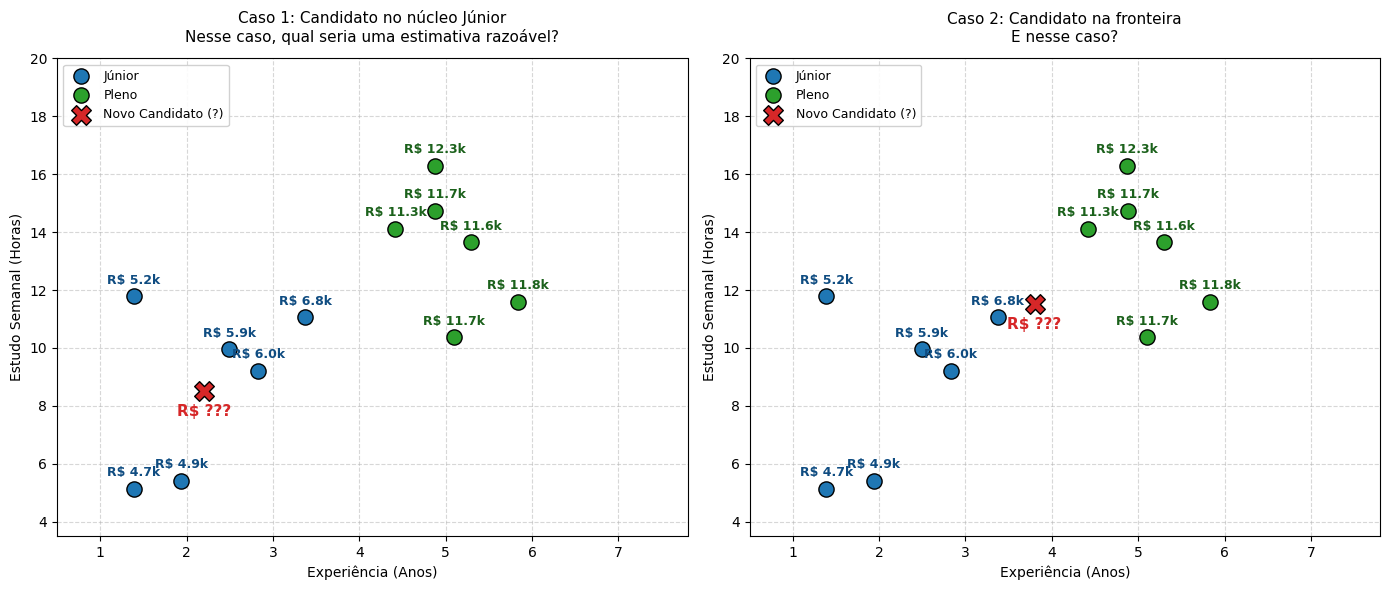

In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ---  DADOS DIDÁTICOS ---
# Juniores: menor experiência / estudo, menores salários
exp_jr = np.random.uniform(1.0, 3.5, 6)
estudo_jr = np.random.uniform(5.0, 12.0, 6)
salario_jr = np.round(3.0 + 0.6 * exp_jr + 0.15 * estudo_jr + np.random.normal(0, 0.2, 6), 1)

# Plenos: maior experiência / estudo, maiores salários
exp_pl = np.random.uniform(4.0, 7.0, 6)
estudo_pl = np.random.uniform(10.0, 18.0, 6)
salario_pl = np.round(5.0 + 0.8 * exp_pl + 0.2 * estudo_pl + np.random.normal(0, 0.3, 6), 1)

# Pontos de Consulta
query_1 = (2.2, 8.5)   # Caso 1: Centro do grupo Júnior
query_2 = (3.8, 11.5)  # Caso 2: Fronteira Júnior/Pleno

# ---  PLOT LADO A LADO ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)

casos = [
    (axes[0], query_1, "Caso 1: Candidato no núcleo Júnior\nNesse caso, qual seria uma estimativa razoável?"),
    (axes[1], query_2, "Caso 2: Candidato na fronteira\nE nesse caso?")
]

for ax, query, titulo in casos:
    # Plot Júnior
    ax.scatter(exp_jr, estudo_jr, color='#1f77b4', s=120, edgecolor='black', zorder=3, label='Júnior')
    for x, y, val in zip(exp_jr, estudo_jr, salario_jr):
        ax.annotate(f"R$ {val:.1f}k", (x, y), textcoords="offset points",
                    xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#0f4c81')

    # Plot Pleno
    ax.scatter(exp_pl, estudo_pl, color='#2ca02c', s=120, edgecolor='black', zorder=3, label='Pleno')
    for x, y, val in zip(exp_pl, estudo_pl, salario_pl):
        ax.annotate(f"R$ {val:.1f}k", (x, y), textcoords="offset points",
                    xytext=(0, 9), ha='center', fontsize=9, fontweight='bold', color='#1b611b')

    # Ponto de Teste (Consulta)
    ax.scatter(query[0], query[1], color='#d62728', marker='X', s=200,
               edgecolor='black', zorder=4, label='Novo Candidato (?)')
    ax.annotate("R$ ???", (query[0], query[1]), textcoords="offset points",
                xytext=(0, -18), ha='center', fontsize=11, fontweight='bold', color='#d62728')

    ax.set_title(titulo, fontsize=11, pad=12)
    ax.set_xlabel("Experiência (Anos)", fontsize=10)
    ax.set_ylabel("Estudo Semanal (Horas)", fontsize=10)
    ax.set_xlim(0.5, 7.8)
    ax.set_ylim(3.5, 20.0)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.savefig("knn_regressao_lado_a_lado.png", dpi=300)
plt.show()